# Sleep Apnea Detection — Leave-One-Patient-Out

CNN + BiGRU, weighted focal loss, LOPO cross-validation over 89 patients.
Reads the **pre-built cache** — no Stage-1 rebuild.

### What changed from `apnea_pipeline_split.ipynb`

| | before | now |
|---|---|---|
| cache | built in-notebook | read from `apnea_cache_resampled` |
| split | 59 / 15 / 15 patients, one fold | **88 train+val / 1 test, × 89 folds** |
| loss | BCE | **weighted focal** (γ=2, capped `pos_weight`) |
| eval tiling | non-overlapping | 50% overlap, averaged |
| removed | LagFusion, structured decoder, 28-figure suite, per-seed reporting, synthetic smoke data, argparse, kagglehub | — |

### Runtime — read this first

89 folds × ~14 epochs. Budget **30–60 h on GPU**. Two mitigations are built in:

- Every fold writes `folds/{pid}.npz` when it finishes. Re-running the notebook
  **skips completed folds**, so you can stop, resume, or run it in batches.
- `MAX_FOLDS = 3` first, confirm the numbers look sane, then set it to `None`.

### Two ways the results are reported

**LOPO mean ± SD** — the per-patient metric averaged over 89 folds. This is what
you asked for and it shows how much performance varies between patients.

**Pooled** — all 89 test patients concatenated, scored once. More stable, and the
number to lead with in a paper: a mean over 89 single-patient F1 scores is
dominated by the mild patients whose F1 is near zero, and is undefined for any
patient with no positive epochs.

Both are printed side by side so the gap between them is visible.

## Cell 1 — Imports and configuration

`CACHE_DIR` points at the existing cache. Nothing is rebuilt.

**Validation inside the 88.** Early stopping and the decision threshold both need
labels the test patient never touched, so of the 88 non-test patients, `VAL_K` are
held out for validation and the remaining `88 - VAL_K` train. They are picked at
evenly spaced severity ranks — deterministic, no RNG, and the validation set spans
the severity range instead of being a lucky draw.

**Weighted focal loss.** `pos_weight` re-weights the positive class; the focal term
`(1-p_t)^γ` concentrates gradient on hard examples. `POS_WEIGHT_CAP = 12` matters:
focal loss with a very large `pos_weight` multiplies two corrections and destabilises
training.

**`EVAL_STRIDE = CHUNK_EPOCHS // 2`.** Evaluation chunks overlap 50% and the
probabilities are averaged. With non-overlapping tiling the first and last epoch of
every chunk sit at a BiGRU boundary — no past for the forward pass, no future for the
backward pass — which fragments events precisely at tile edges. One extra forward
pass buys that back.

In [2]:
# =========================================================================
# CELL 1 — imports and configuration
# =========================================================================
import os, re, gc, glob, json, time, random, warnings, sys, subprocess, importlib.util

if importlib.util.find_spec("torchinfo") is None:          # for the model summary
    _c = [sys.executable, "-m", "pip", "install", "-q", "torchinfo"]
    try:
        subprocess.check_call(_c)
    except Exception:
        subprocess.call(_c + ["--break-system-packages"])

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, average_precision_score,
                             precision_recall_curve, matthews_corrcoef,
                             cohen_kappa_score, brier_score_loss, roc_curve)
from scipy.stats import pearsonr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- paths --------------------------------------------------------------
PROJECT_DIR = "/home/nishant/apneastudyproject"
CACHE_DIR   = os.environ.get("APNEA_CACHE",  os.path.join(PROJECT_DIR, "apnea_cache_resampled"))
OUT_DIR     = os.environ.get("APNEA_RESULT", os.path.join(PROJECT_DIR, "leave_one_out_output"))
FOLD_DIR    = os.path.join(OUT_DIR, "folds")
FIG_DIR     = os.path.join(OUT_DIR, "figures")
for d in (OUT_DIR, FOLD_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# ---- LOPO ---------------------------------------------------------------
MAX_FOLDS   = None       # None = all patients. Set 3 for a smoke run first.
VAL_K       = 12         # patients held out of the 88 for early stopping + threshold
RESUME      = True       # skip folds whose result file already exists
SEED        = 42

# ---- sequence -----------------------------------------------------------
WINDOW_SEC   = 30
CHUNK_EPOCHS = 40                    # 40 x 30 s = 20 min of context
TRAIN_STRIDE = 10                    # 75% overlap -> more optimizer steps
EVAL_STRIDE  = CHUNK_EPOCHS // 2     # 50% overlap, averaged (see markdown)

# ---- model --------------------------------------------------------------
WIDTH, GRU_HIDDEN, GRU_LAYERS = 64, 96, 2
DILATIONS, KERNEL, SE_REDUCTION, DROPOUT = (1, 2, 4, 8, 16, 32), 9, 8, 0.2
STEM_STRIDE = 2
USE_BURDEN_HEAD, USE_BOUNDARY_HEAD = True, True

# ---- weighted focal loss ------------------------------------------------
FOCAL_GAMMA     = 2.0
POS_WEIGHT_CAP  = 12.0
BURDEN_WEIGHT   = 0.3
BOUNDARY_WEIGHT = 0.2
BOUNDARY_POS_WEIGHT = 8.0

# ---- training -----------------------------------------------------------
EPOCHS, PATIENCE, BATCH_SIZE = 14, 5, 16
LR, WEIGHT_DECAY, GRAD_CLIP = 2e-3, 3e-4, 3.0
NUM_WORKERS = 0 if os.name == "nt" else 2

AUGMENT = True
NOISE_STD, SCALE_JITTER, CHANNEL_DROPOUT_P = 0.03, 0.10, 0.20
TIME_MASK_P, TIME_MASK_FRAC = 0.5, 0.10
FEAT_CLIP, NORM_SAMPLE_EPOCHS = 8.0, 8000

# ---- evaluation ---------------------------------------------------------
EPH_BINS = [5.0, 15.0, 30.0]     # events per hour -> severity band
SEVERITY_NAMES = ["normal", "mild", "moderate", "severe"]
N_CALIB_BINS = 10

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"cache  {CACHE_DIR}")
print(f"output {OUT_DIR}")
print(f"device {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})"
                            if DEVICE.type == "cuda" else "  [!] CPU: expect ~20x runtime"))

cache  /home/nishant/apneastudyproject/apnea_cache_resampled
output /home/nishant/apneastudyproject/leave_one_out_output
device cuda (NVIDIA GeForce RTX 4090)


## Cell 2 — Load the pre-built cache

The loader discovers `*.npz` files, pulls the patient ID out of each filename with
`re.search(r"(SN\d+)")`, and reads them. It does **not** assume a channel count or a
sample rate — `N_RESP`, `RESP_SPE`, `N_SLOW`, `SLOW_SPE` and `N_FEAT` are all read
off the arrays. If your cache has a different layout the model adapts instead of
crashing 20 minutes in.

Expected keys per file (missing optional ones are synthesised):

| key | shape | required |
|---|---|---|
| `resp` | (n, C_r, S_r) | yes |
| `slow` | (n, C_s, S_s) | yes |
| `y` | (n,) | yes |
| `feat` | (n, F) | no — falls back to no features |
| `onset` / `offset` | (n,) | no — recomputed from `y` |
| `mask_resp` / `mask_slow` | (C_r,) / (C_s,) | no — assumed all present |

`boundary_targets` marks where events start and end. It is computed over the **whole
night** and sliced afterwards; computing it inside a chunk would manufacture a false
onset at every chunk edge.

In [3]:
# =========================================================================
# CELL 2 — load the pre-built cache
# =========================================================================
def boundary_targets(y):
    """onset[t]=1 where an event starts, offset[t]=1 where it ends."""
    y = np.asarray(y).astype(np.int8)
    onset, offset = np.zeros(len(y), np.float32), np.zeros(len(y), np.float32)
    if len(y) == 0:
        return onset, offset
    prev = np.concatenate(([0], y[:-1]))
    nxt = np.concatenate((y[1:], [0]))
    onset[(y == 1) & (prev == 0)] = 1.0
    offset[(y == 1) & (nxt == 0)] = 1.0
    return onset, offset


def load_cache(cache_dir):
    files = sorted(glob.glob(os.path.join(cache_dir, "*.npz")))
    if not files:
        raise FileNotFoundError(f"no .npz files in {cache_dir}")
    cache = {}
    for f in files:
        m = re.search(r"(SN\d+)", os.path.basename(f))
        if not m:
            continue
        pid = m.group(1)
        with np.load(f, allow_pickle=True) as z:
            if not {"resp", "slow", "y"} <= set(z.files):
                print(f"  [skip] {pid}: missing resp/slow/y (has {list(z.files)})")
                continue
            resp, slow = z["resp"], z["slow"]
            y = np.asarray(z["y"]).astype(np.int8)
            n = min(len(y), resp.shape[0], slow.shape[0])
            d = dict(resp=resp[:n].copy(), slow=slow[:n].copy(), y=y[:n])
            d["feat"] = (np.asarray(z["feat"], np.float32)[:n] if "feat" in z.files
                         else np.zeros((n, 0), np.float32))
            if "onset" in z.files and "offset" in z.files:
                d["onset"] = np.asarray(z["onset"], np.float32)[:n]
                d["offset"] = np.asarray(z["offset"], np.float32)[:n]
            else:
                d["onset"], d["offset"] = boundary_targets(d["y"])
            d["mask_resp"] = (np.asarray(z["mask_resp"], np.float32) if "mask_resp" in z.files
                              else np.ones(resp.shape[1], np.float32))
            d["mask_slow"] = (np.asarray(z["mask_slow"], np.float32) if "mask_slow" in z.files
                              else np.ones(slow.shape[1], np.float32))
        if n >= CHUNK_EPOCHS and y[:n].sum() > 0:
            cache[pid] = d
        else:
            print(f"  [skip] {pid}: {n} epochs, {int(y[:n].sum())} positive")
    return cache


def find_events(seq):
    b = np.asarray(seq).astype(int)
    if b.size == 0:
        return []
    dd = np.diff(np.concatenate(([0], b, [0])))
    return list(zip(np.flatnonzero(dd == 1).tolist(),
                    (np.flatnonzero(dd == -1) - 1).tolist()))


def events_per_hour(y):
    """Events per hour of RECORDING (no sleep staging in this dataset)."""
    return len(find_events(y)) / max(len(y) * WINDOW_SEC / 3600.0, 1e-6)


def severity_of(a):
    return int(np.searchsorted(EPH_BINS, a, side="right"))


CACHE = load_cache(CACHE_DIR)
PIDS = sorted(CACHE, key=lambda p: int(p[2:]))

# layout is READ FROM THE DATA, not assumed
_d0 = CACHE[PIDS[0]]
N_RESP, RESP_SPE = _d0["resp"].shape[1], _d0["resp"].shape[2]
N_SLOW, SLOW_SPE = _d0["slow"].shape[1], _d0["slow"].shape[2]
N_FEAT = _d0["feat"].shape[1]
N_MASK = N_RESP + N_SLOW

COHORT = pd.DataFrame([dict(patient=p, n_epochs=len(CACHE[p]["y"]),
                            apnea_ratio=float(CACHE[p]["y"].mean()),
                            events_per_hour=events_per_hour(CACHE[p]["y"]),
                            severity=SEVERITY_NAMES[severity_of(events_per_hour(CACHE[p]["y"]))])
                       for p in PIDS])
COHORT.to_csv(os.path.join(OUT_DIR, "cohort.csv"), index=False)

n_ep = int(COHORT.n_epochs.sum())
print(f"\n{len(PIDS)} patients | {n_ep:,} epochs ({n_ep*WINDOW_SEC/3600:.0f} h) | "
      f"apnea {100*sum(CACHE[p]['y'].sum() for p in PIDS)/n_ep:.1f}%")
print(f"resp ({N_RESP}, {RESP_SPE}) @ {RESP_SPE/WINDOW_SEC:.0f} Hz | "
      f"slow ({N_SLOW}, {SLOW_SPE}) @ {SLOW_SPE/WINDOW_SEC:.0f} Hz | {N_FEAT} features")
print(COHORT.severity.value_counts().reindex(SEVERITY_NAMES).fillna(0).astype(int).to_string())


89 patients | 85,288 epochs (711 h) | apnea 24.5%
resp (5, 960) @ 32 Hz | slow (3, 120) @ 4 Hz | 33 features
severity
normal      30
mild        57
moderate     2
severe       0


## Cell 3 — Dataset

Yields contiguous chunks of `CHUNK_EPOCHS` epochs with one label per epoch — 40
predictions per forward pass rather than one.

**`gpos`** is the global position index. Batches are shuffled, so each epoch carries
the index it must be scattered back to when predictions are reassembled into night
order.

**Five augmentations, all through `torch`'s RNG, never `np.random`.** PyTorch's
DataLoader reseeds torch's generator per worker per epoch but not NumPy's — forked
workers inherit NumPy state identically, so `np.random` would replay the same
augmentation every epoch in every worker and nothing would error.

1. Random chunk offset — a real time shift, not `np.roll` (which splices 3 AM onto 11 PM).
2. Gaussian noise. 3. Per-channel scale jitter.
4. Channel dropout — the mask bit is dropped too, so augmented absence matches real absence.
5. Time masking — zeros a span in **both** streams at the same wall-clock position,
   forcing the model to spread its evidence rather than lean on one stream.

`estimate_stats` computes normalization statistics from **training patients only**.

In [4]:
# =========================================================================
# CELL 3 — dataset
# =========================================================================
class ApneaSeqDataset(Dataset):
    def __init__(self, cache, pids, chunk, stride, stats, augment=False):
        self.cache, self.chunk, self.augment = cache, chunk, augment
        self.pids = [p for p in pids if p in cache]
        (self.rm, self.rs, self.sm, self.ss, self.fm, self.fs) = stats

        self.items, self.offset, self.bounds, labels, off = [], {}, [], [], 0
        for pid in self.pids:
            y = np.asarray(cache[pid]["y"]).astype(np.int8)
            n = len(y)
            self.offset[pid] = off
            self.bounds.append((pid, off, off + n))
            labels.append(y)
            if n >= chunk:
                starts = list(range(0, n - chunk + 1, stride))
                if starts[-1] != n - chunk:
                    starts.append(n - chunk)
            else:
                starts = [0]
            self.items += [(pid, s) for s in starts]
            off += n
        self.total_epochs = off
        self.labels_flat = np.concatenate(labels) if labels else np.zeros(0, np.int8)

    def __len__(self):
        return len(self.items)

    def _slice(self, arr, s, m, spe, nch):
        seg = np.asarray(arr[s:s + m], np.float32).transpose(1, 0, 2).reshape(nch, m * spe)
        if m < self.chunk:
            seg = np.pad(seg, ((0, 0), (0, (self.chunk - m) * spe)))
        return seg

    def __getitem__(self, i):
        pid, s = self.items[i]
        d = self.cache[pid]
        n = len(d["y"])
        if self.augment and n > self.chunk:                    # real time shift
            j = int(torch.randint(-self.chunk // 2, self.chunk // 2 + 1, (1,)).item())
            s = int(np.clip(s + j, 0, n - self.chunk))
        m = min(s + self.chunk, n) - s

        resp = torch.from_numpy((self._slice(d["resp"], s, m, RESP_SPE, N_RESP)
                                 - self.rm[:, None]) / self.rs[:, None])
        slow = torch.from_numpy((self._slice(d["slow"], s, m, SLOW_SPE, N_SLOW)
                                 - self.sm[:, None]) / self.ss[:, None])
        mask = torch.from_numpy(np.concatenate([d["mask_resp"], d["mask_slow"]]
                                               ).astype(np.float32).copy())

        feats = np.zeros((self.chunk, N_FEAT), np.float32)
        if N_FEAT:
            fseg = (np.asarray(d["feat"][s:s + m], np.float32) - self.fm) / self.fs
            feats[:m] = np.clip(fseg, -FEAT_CLIP, FEAT_CLIP)

        y = np.zeros(self.chunk, np.float32); on = np.zeros(self.chunk, np.float32)
        of = np.zeros(self.chunk, np.float32); vl = np.zeros(self.chunk, np.float32)
        y[:m] = d["y"][s:s + m]; on[:m] = d["onset"][s:s + m]
        of[:m] = d["offset"][s:s + m]; vl[:m] = 1.0
        gpos = np.full(self.chunk, -1, np.int64)
        gpos[:m] = np.arange(s, s + m) + self.offset[pid]

        if self.augment:
            # torch RNG only: DataLoader reseeds it per worker, numpy's it does not
            resp = resp + torch.randn_like(resp) * NOISE_STD
            slow = slow + torch.randn_like(slow) * NOISE_STD
            resp = resp * (1 + (torch.rand(N_RESP, 1) * 2 - 1) * SCALE_JITTER)
            slow = slow * (1 + (torch.rand(N_SLOW, 1) * 2 - 1) * SCALE_JITTER)
            dr, ds = torch.rand(N_RESP) < CHANNEL_DROPOUT_P, torch.rand(N_SLOW) < CHANNEL_DROPOUT_P
            if dr.any() and not dr.all():
                resp[dr] = 0.0; mask[:N_RESP][dr] = 0.0      # drop the mask bit too
            if ds.any() and not ds.all():
                slow[ds] = 0.0; mask[N_RESP:][ds] = 0.0
            if float(torch.rand(1)) < TIME_MASK_P:
                w = int(torch.randint(1, max(2, int(TIME_MASK_FRAC * self.chunk)) + 1, (1,)))
                st = int(torch.randint(0, max(1, self.chunk - w), (1,)))
                resp[:, st * RESP_SPE:(st + w) * RESP_SPE] = 0.0   # same wall-clock span
                slow[:, st * SLOW_SPE:(st + w) * SLOW_SPE] = 0.0   # in both streams

        return (resp, slow, mask, torch.from_numpy(feats), torch.from_numpy(y),
                torch.from_numpy(on), torch.from_numpy(of),
                torch.from_numpy(vl), torch.from_numpy(gpos))


def estimate_stats(cache, pids, n_sample=NORM_SAMPLE_EPOCHS):
    """Mean/std per channel and per feature, from TRAINING patients only."""
    rng = np.random.default_rng(SEED)
    pids = [p for p in pids if p in cache]
    budget = max(1, n_sample // max(1, len(pids)))
    rs = rq = ss = sq = fs_ = fq = 0.0
    rc = sc = fc = 0
    for pid in pids:
        d = cache[pid]
        n = d["resp"].shape[0]
        idx = np.sort(rng.choice(n, size=min(budget, n), replace=False))
        r = np.asarray(d["resp"][idx], np.float64); s = np.asarray(d["slow"][idx], np.float64)
        rs = rs + r.sum((0, 2)); rq = rq + (r ** 2).sum((0, 2)); rc += len(idx) * r.shape[2]
        ss = ss + s.sum((0, 2)); sq = sq + (s ** 2).sum((0, 2)); sc += len(idx) * s.shape[2]
        if N_FEAT:
            f = np.asarray(d["feat"][idx], np.float64)
            fs_ = fs_ + f.sum(0); fq = fq + (f ** 2).sum(0); fc += len(idx)
    rc, sc, fc = max(rc, 1), max(sc, 1), max(fc, 1)
    rm, sm = rs / rc, ss / sc
    fm = (fs_ / fc) if N_FEAT else np.zeros(1)
    fsd = np.sqrt(np.clip(fq / fc - fm ** 2, 1e-6, None)) if N_FEAT else np.ones(1)
    return (rm.astype(np.float32),
            np.sqrt(np.clip(rq / rc - rm ** 2, 1e-8, None)).astype(np.float32),
            sm.astype(np.float32),
            np.sqrt(np.clip(sq / sc - sm ** 2, 1e-8, None)).astype(np.float32),
            fm.astype(np.float32), fsd.astype(np.float32))

print("dataset ready")

dataset ready


## Cell 4 — Model and weighted focal loss

Dual-rate CNN encoder → BiGRU over epochs → per-epoch heads. Unchanged from the
validated architecture except that LagFusion is gone (it was disabled anyway, and a
bidirectional GRU can already learn any fixed offset).

**Receptive field.** With kernel 9 and dilations 1…32:
$$\text{RF} = 1 + 2\lfloor k/2 \rfloor \sum_\ell d_\ell = 1 + 8(1+2+4+8+16+32) = 505 \text{ taps}$$
At 16 Hz effective (32 Hz, stem stride 2) that is **31.6 s** — long enough to contain
a whole apnea plus its lagged desaturation.

**Depthwise-separable convolutions.** At C=64, k=9 a full conv is 36,864 parameters;
separable is 4,672 — 7.9× fewer. That saving is what makes the six-block dilation
ladder affordable.

**GroupNorm, not BatchNorm.** Batch 16 at ~24% positives gives noisy batch statistics,
and BatchNorm behaves differently in train vs eval — which scale-jitter augmentation
makes worse. GroupNorm has no train/eval discrepancy.

**Mean *and* max epoch pooling.** The labels are any-overlap: an epoch is positive if
an event merely touches it, which makes the label mathematically a **max**. A 10-second
apnea inside a 30-second epoch is attenuated ~3× by averaging alone.

**The mask joins at the head, not the encoder.** It is constant along time, so
convolving thousands of copies extracts nothing — and sensor availability is close to
a patient fingerprint, which is a leakage path under a patient-level split.

### Weighted focal loss

$$\mathcal{L} = -\frac{1}{\sum v_t}\sum_t v_t \left[ w^+ y_t (1-p_t)^\gamma \log p_t + (1-y_t)\, p_t^\gamma \log(1-p_t) \right]$$

Two mechanisms doing different jobs. **`pos_weight`** $w^+ = n_0/n_1$ corrects the
class imbalance — without it the model can score 75% accuracy by predicting "normal"
everywhere. **The focal term** $(1-p_t)^\gamma$ down-weights easy examples: at
$p_t = 0.99$ and $\gamma = 2$ the gradient is scaled by $10^{-4}$, so the loss
concentrates on the boundary epochs where the any-overlap labels are noisiest.

`pos_weight` is capped at 12 because the two corrections **multiply**. An uncapped
weight of 40 combined with focal down-weighting of the (now dominant) easy negatives
sends the effective positive weight into the hundreds and training diverges.

Reduction is sum-over-valid ÷ count-of-valid, so a padded chunk tail contributes nothing.

Total loss = main + 0.3 · burden + 0.2 · boundary. The **burden head** regresses each
chunk's apnea fraction, forcing the per-epoch head to also be globally coherent. The
**boundary heads** predict onset and offset, asking a question the main head never has
to answer; they use `pos_weight = 8` because boundaries are ~1–2% of epochs against
~24% positives.

In [5]:
# =========================================================================
# CELL 4 — model and weighted focal loss
# =========================================================================
def gn_groups(c, preferred=8):
    for g in range(min(preferred, c), 0, -1):
        if c % g == 0:
            return g
    return 1


class SEBlock1D(nn.Module):
    """Learned per-channel gate: the network decides which features matter."""
    def __init__(self, ch, reduction=SE_REDUCTION):
        super().__init__()
        h = max(4, ch // reduction)
        self.fc = nn.Sequential(nn.Linear(ch, h), nn.GELU(), nn.Linear(h, ch), nn.Sigmoid())

    def forward(self, x):
        b, c, _ = x.shape
        return x * self.fc(x.mean(-1)).view(b, c, 1)


class SEResSepBlock(nn.Module):
    """Dilated depthwise-separable residual block + squeeze-excitation."""
    def __init__(self, ch, kernel=KERNEL, dilation=1, dropout=DROPOUT):
        super().__init__()
        pad = dilation * (kernel // 2)
        self.dw = nn.Conv1d(ch, ch, kernel, padding=pad, dilation=dilation,
                            groups=ch, bias=False)
        self.pw = nn.Conv1d(ch, ch, 1, bias=False)
        self.n1 = nn.GroupNorm(gn_groups(ch), ch)
        self.n2 = nn.GroupNorm(gn_groups(ch), ch)
        self.se, self.act, self.drop = SEBlock1D(ch), nn.GELU(), nn.Dropout(dropout)

    def forward(self, x):
        h = self.act(self.n1(self.dw(x)))
        h = self.se(self.n2(self.pw(h)))
        return self.act(x + self.drop(h))


class StreamEncoder(nn.Module):
    """Signal -> one embedding per 30 s epoch."""
    def __init__(self, in_ch, width, spe, dilations=DILATIONS, stride=STEM_STRIDE):
        super().__init__()
        layers = [nn.Conv1d(in_ch, width, 7, stride=2, padding=3, bias=False),
                  nn.GroupNorm(gn_groups(width), width), nn.GELU()]
        s = 2
        while s < stride:
            layers += [nn.Conv1d(width, width, 5, stride=2, padding=2, bias=False),
                       nn.GroupNorm(gn_groups(width), width), nn.GELU()]
            s *= 2
        self.stem = nn.Sequential(*layers)
        self.body = nn.Sequential(*[SEResSepBlock(width, dilation=d) for d in dilations])
        self.spe_out = max(1, spe // s)
        self.out_dim = 2 * width                      # mean + max pooling

    def forward(self, x):
        h = self.body(self.stem(x))
        b, w, t = h.shape
        n_ep = max(1, t // self.spe_out)
        h = h[:, :, :n_ep * self.spe_out].view(b, w, n_ep, self.spe_out)
        # mean AND max: any-overlap labels are effectively a max over the epoch
        return torch.cat([h.mean(-1), h.amax(-1)], dim=1).transpose(1, 2)


class ApneaSegmenter(nn.Module):
    def __init__(self):
        super().__init__()
        self.resp_enc = StreamEncoder(N_RESP, WIDTH, RESP_SPE)
        self.slow_enc = StreamEncoder(N_SLOW, WIDTH, SLOW_SPE)
        gru_in = self.resp_enc.out_dim + self.slow_enc.out_dim + N_FEAT
        self.temporal = nn.GRU(gru_in, GRU_HIDDEN, num_layers=GRU_LAYERS,
                               batch_first=True, bidirectional=True,
                               dropout=DROPOUT if GRU_LAYERS > 1 else 0.0)
        self.norm, self.drop = nn.LayerNorm(2 * GRU_HIDDEN), nn.Dropout(DROPOUT)
        # the mask joins HERE, not in the encoder: constant along time, and
        # sensor availability is a patient fingerprint = a leakage path
        self.head = nn.Linear(2 * GRU_HIDDEN + N_MASK, 3 if USE_BOUNDARY_HEAD else 1)
        self.burden = nn.Sequential(nn.Linear(2 * GRU_HIDDEN, GRU_HIDDEN), nn.GELU(),
                                    nn.Dropout(DROPOUT), nn.Linear(GRU_HIDDEN, 1)
                                    ) if USE_BURDEN_HEAD else None

    def forward(self, resp, slow, mask, feats):
        h = torch.cat([self.resp_enc(resp), self.slow_enc(slow)], dim=-1)
        if N_FEAT:
            h = torch.cat([h, feats], dim=-1)
        h, _ = self.temporal(h)
        h = self.drop(self.norm(h))
        m = mask[:, None, :].expand(-1, h.shape[1], -1)
        out = self.head(torch.cat([h, m], dim=-1))
        apnea = out[..., 0]
        onset = out[..., 1] if USE_BOUNDARY_HEAD else None
        offset = out[..., 2] if USE_BOUNDARY_HEAD else None
        burden = self.burden(h.mean(1)).squeeze(-1) if self.burden is not None else None
        return apnea, onset, offset, burden


def weighted_focal(logits, targets, valid, pos_weight, gamma=FOCAL_GAMMA):
    """pos_weight fixes the imbalance; (1-p_t)^gamma concentrates on hard epochs."""
    bce = F.binary_cross_entropy_with_logits(logits, targets,
                                             pos_weight=pos_weight, reduction="none")
    p = torch.sigmoid(logits)
    pt = p * targets + (1 - p) * (1 - targets)
    bce = bce * (1 - pt).clamp(min=1e-6) ** gamma
    return (bce * valid).sum() / valid.sum().clamp(min=1.0)


def total_loss(apnea, onset, offset, burden, y, y_on, y_off, valid, pos_weight, bnd_weight):
    main = weighted_focal(apnea, y, valid, pos_weight)
    total, parts = main, {"main": float(main.detach())}
    if burden is not None:
        tgt = (y * valid).sum(1) / valid.sum(1).clamp(min=1.0)   # chunk apnea fraction
        aux = F.binary_cross_entropy_with_logits(burden, tgt)
        total = total + BURDEN_WEIGHT * aux
        parts["burden"] = float(aux.detach())
    if onset is not None:
        b1 = F.binary_cross_entropy_with_logits(onset, y_on, pos_weight=bnd_weight,
                                                reduction="none")
        b2 = F.binary_cross_entropy_with_logits(offset, y_off, pos_weight=bnd_weight,
                                                reduction="none")
        bnd = ((b1 + b2) * valid).sum() / valid.sum().clamp(min=1.0) / 2.0
        total = total + BOUNDARY_WEIGHT * bnd
        parts["boundary"] = float(bnd.detach())
    return total, parts


_m = ApneaSegmenter()
print(f"ApneaSegmenter: {sum(p.numel() for p in _m.parameters()):,} parameters")
print(f"receptive field: {1 + 2*(KERNEL//2)*sum(DILATIONS)} taps "
      f"= {(1 + 2*(KERNEL//2)*sum(DILATIONS)) / (RESP_SPE/WINDOW_SEC/STEM_STRIDE):.1f} s")
del _m

ApneaSegmenter: 485,692 parameters
receptive field: 505 taps = 31.6 s


## Cell 5 — Model summary: the whole pipeline, layer by layer

`torchinfo.summary` is the PyTorch equivalent of Keras's `model.summary()`. It runs one
real forward pass with hooks attached, so the shapes it prints are **measured, not
inferred** — if a reshape is wrong, it shows up here rather than 20 minutes into training.

Three views are printed:

1. **Layer table** — every module with its input shape, output shape and parameter
   count. Read the `Output Shape` column downward to follow one batch through the network.
2. **Parameter budget by component** — where the capacity actually sits. On this
   architecture the BiGRU holds ~80% of the parameters and the convolutions only ~16%,
   which matches the physiology: apnea is defined by a *pattern over time*, not by a
   static waveform.
3. **Tensor shape walkthrough** — the same journey in one table, annotated with what
   each step means physically.

### The receptive field, which is the design constraint

$$\text{RF} = 1 + 2\left\lfloor \frac{k}{2}\right\rfloor \sum_\ell d_\ell
            = 1 + 8\,(1+2+4+8+16+32) = 505 \text{ taps}$$

At 32 Hz with stem stride 2 the encoder runs at 16 Hz effective, so 505 taps ≈ **31.6 s**
for the respiratory stream — long enough to contain a whole apnea *plus* the desaturation
that trails it by 10–30 s. The slow stream at 4 Hz / stride 2 reaches ~252 s.

In [6]:
# =========================================================================
# CELL 5 — model summary
# =========================================================================
_m = ApneaSegmenter().to(DEVICE)
_B = 2
_dummy = (torch.zeros(_B, N_RESP, CHUNK_EPOCHS * RESP_SPE, device=DEVICE),
          torch.zeros(_B, N_SLOW, CHUNK_EPOCHS * SLOW_SPE, device=DEVICE),
          torch.ones(_B, N_MASK, device=DEVICE),
          torch.zeros(_B, CHUNK_EPOCHS, N_FEAT, device=DEVICE))

try:
    from torchinfo import summary
    print(summary(_m, input_data=list(_dummy), depth=3, verbose=0,
                  col_names=("input_size", "output_size", "num_params"),
                  row_settings=("var_names",)))
except Exception as e:
    print(f"[torchinfo unavailable: {e}] falling back to a parameter table\n")
    for n, mod in _m.named_children():
        print(f"  {n:12s} {sum(p.numel() for p in mod.parameters()):>9,}")

# ---- parameter budget by component --------------------------------------
tot = sum(p.numel() for p in _m.parameters())
print(f"\n{'='*62}\n  PARAMETER BUDGET — {tot:,} total\n{'='*62}")
for name, mod in _m.named_children():
    n = sum(p.numel() for p in mod.parameters())
    if n:
        print(f"  {name:14s} {n:>9,}  {100*n/tot:5.1f}%")
print(f"\n  receptive field: 1 + 8*(1+2+4+8+16+32) = {1 + 8*sum(DILATIONS)} taps")
print(f"    respiratory @ {RESP_SPE//WINDOW_SEC} Hz / stride {STEM_STRIDE} "
      f"-> {(1 + 8*sum(DILATIONS)) * STEM_STRIDE / (RESP_SPE/WINDOW_SEC):.1f} s")
print(f"    slow        @ {SLOW_SPE//WINDOW_SEC} Hz / stride {STEM_STRIDE} "
      f"-> {(1 + 8*sum(DILATIONS)) * STEM_STRIDE / (SLOW_SPE/WINDOW_SEC):.0f} s")

# ---- tensor shape walkthrough -------------------------------------------
with torch.no_grad():
    _r = _m.resp_enc(_dummy[0]); _s = _m.slow_enc(_dummy[1])
    _h = torch.cat([_r, _s], -1)
    _hf = torch.cat([_h, _dummy[3]], -1) if N_FEAT else _h
    _g, _ = _m.temporal(_hf)
    _out = _m(*_dummy)

W = _m.resp_enc.out_dim // 2
walk = pd.DataFrame([
    ("cache on disk",      f"(n, {N_RESP}, {RESP_SPE}) + (n, {N_SLOW}, {SLOW_SPE})",
     "one night, per 30-s epoch, two sample rates"),
    ("one chunk",          f"({N_RESP}, {CHUNK_EPOCHS*RESP_SPE})",
     f"{CHUNK_EPOCHS} epochs stitched = {CHUNK_EPOCHS*WINDOW_SEC//60} min of signal"),
    ("batch in",           str(tuple(_dummy[0].shape)),  "respiratory stream"),
    ("  + slow stream",    str(tuple(_dummy[1].shape)),  "SpO2, pulse, ECG envelope"),
    ("resp encoder out",   str(tuple(_r.shape)),
     f"one embedding per epoch: mean+max pooling of {W} channels"),
    ("slow encoder out",   str(tuple(_s.shape)),         "same, from the slow stream"),
    ("concat streams",     str(tuple(_h.shape)),         "the two encoders fused"),
    ("+ AASM features",    str(tuple(_hf.shape)),        f"{N_FEAT} rule-based features injected"),
    ("BiGRU out",          str(tuple(_g.shape)),
     f"{GRU_LAYERS} layers x {GRU_HIDDEN} hidden, both directions"),
    ("apnea logits",       str(tuple(_out[0].shape)),    "ONE logit per 30-s epoch"),
    ("onset / offset",     str(tuple(_out[1].shape)),    "auxiliary boundary heads"),
    ("burden",             str(tuple(_out[3].shape)),    "one apnea-fraction per chunk"),
], columns=["stage", "shape", "meaning"])
print(f"\n{'='*100}\n  TENSOR SHAPE WALKTHROUGH (batch = {_B})\n{'='*100}")
print(walk.to_string(index=False))
print(f"\n  sigmoid(apnea logits) -> probability per epoch -> >= threshold -> 0/1")

del _m, _dummy, _r, _s, _h, _hf, _g, _out
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Layer (type (var_name))                       Input Shape               Output Shape              Param #
ApneaSegmenter (ApneaSegmenter)               [2, 5, 38400]             [2, 40]                   --
├─StreamEncoder (resp_enc)                    [2, 5, 38400]             [2, 40, 128]              --
│    └─Sequential (stem)                      [2, 5, 38400]             [2, 64, 19200]            --
│    │    └─Conv1d (0)                        [2, 5, 38400]             [2, 64, 19200]            2,240
│    │    └─GroupNorm (1)                     [2, 64, 19200]            [2, 64, 19200]            128
│    │    └─GELU (2)                          [2, 64, 19200]            [2, 64, 19200]            --
│    └─Sequential (body)                      [2, 64, 19200]            [2, 64, 19200]            --
│    │    └─SEResSepBlock (0)                 [2, 64, 19200]            [2, 64, 19200]            6,024
│    │    └─SEResSepBlock (1)                 [2, 64, 19200]            [2, 64,

## Cell 6 — Train and evaluate one fold

### The split inside a fold

For test patient $p$: the other 88 are ranked by events per hour, `VAL_K` are taken at
**evenly spaced ranks** for validation, and the remaining 76 train. Evenly spaced
ranks rather than a random draw because prevalence spans 1% to 73% across this
cohort — a random validation set of 12 could be all mild patients, and the early
stopping point and threshold would then be tuned for the wrong regime.

No RNG is involved in the split, so it is reproducible without a seed.

### `run_pass`

In eval mode, per-epoch probabilities are scattered back into a flat patient-ordered
array with `np.add.at` and averaged where chunks overlap. `np.add.at` is the
unbuffered form — `psum[g] += p` silently keeps only one contribution per repeated
index, which with 50% overlap would be half the data.

`scaler.unscale_(optimizer)` before `clip_grad_norm_` is required: under mixed
precision the gradients are still multiplied by the loss scale at that point, and
clipping unscaled gradients would clip to an arbitrary, scale-dependent threshold.

### Model selection and the threshold

Both come from **validation**, never from the test patient. Early stopping keeps the
weights with the best validation F1; `best_f1_threshold` then sweeps the
precision-recall curve for the F1-optimal cut. That single scalar is what turns the
test patient's probabilities into 0/1.

`OneCycleLR` gets `total_steps = EPOCHS * len(train_loader)` so the anneal actually
completes rather than being cut off mid-schedule by early stopping.

In [7]:
# =========================================================================
# CELL 6 — one LOPO fold
# =========================================================================
def make_fold(test_pid):
    """Test = 1 patient. The other 88 split into VAL_K validation + rest training."""
    others = [p for p in PIDS if p != test_pid]
    ranks = np.argsort([events_per_hour(CACHE[p]["y"]) for p in others], kind="stable")
    ordered = [others[i] for i in ranks]
    vi = sorted(set(np.linspace(0, len(ordered) - 1, VAL_K).round().astype(int).tolist()))
    val = [ordered[i] for i in vi]
    train = [p for i, p in enumerate(ordered) if i not in set(vi)]
    return train, val, [test_pid]


def best_f1_threshold(labels, probs):
    """F1-optimal cut. Only ever called on VALIDATION."""
    labels, probs = np.asarray(labels), np.asarray(probs)
    if labels.size == 0 or len(np.unique(labels)) < 2:
        return 0.5, 0.0
    prec, rec, thr = precision_recall_curve(labels, probs)
    if len(thr) == 0:
        return 0.5, 0.0
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    i = int(np.nanargmax(f1s[:-1]))
    return float(thr[i]), float(f1s[i])


def run_pass(model, loader, pos_weight, bnd_weight, optimizer, scaler,
             scheduler, train_mode, total_epochs=None):
    model.train(mode=train_mode)
    loss_sum = seen = 0.0
    if not train_mode:
        psum = np.zeros(total_epochs); pcnt = np.zeros(total_epochs)

    for resp, slow, mask, feats, y, y_on, y_off, valid, gpos in loader:
        resp, slow = resp.to(DEVICE, non_blocking=True), slow.to(DEVICE, non_blocking=True)
        mask, feats = mask.to(DEVICE), feats.to(DEVICE)
        y, y_on, y_off, valid = (y.to(DEVICE), y_on.to(DEVICE),
                                 y_off.to(DEVICE), valid.to(DEVICE))
        with torch.set_grad_enabled(train_mode):
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                apnea, onset, offset, burden = model(resp, slow, mask, feats)
                loss, _ = total_loss(apnea, onset, offset, burden, y, y_on, y_off,
                                     valid, pos_weight, bnd_weight)
            if train_mode:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)          # must precede clipping
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(optimizer); scaler.update()
                if scheduler is not None:
                    scheduler.step()

        nv = float(valid.sum().item())
        loss_sum += float(loss.item()) * nv; seen += nv
        if not train_mode:
            p = torch.sigmoid(apnea.float()).detach().cpu().numpy().ravel()
            g = gpos.numpy().ravel()
            keep = (valid.detach().cpu().numpy().ravel() > 0.5) & (g >= 0)
            np.add.at(psum, g[keep], p[keep])       # unbuffered: handles overlap
            np.add.at(pcnt, g[keep], 1.0)

    avg = loss_sum / max(seen, 1.0)
    if train_mode:
        return avg, None
    return avg, psum / np.maximum(pcnt, 1.0)


def train_fold(test_pid, verbose=True):
    """Train on 76, early-stop and threshold on 12, predict the 1 held-out patient."""
    tr_p, va_p, te_p = make_fold(test_pid)
    random.seed(SEED); np.random.seed(SEED)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

    stats = estimate_stats(CACHE, tr_p)             # TRAIN ONLY
    tr = ApneaSeqDataset(CACHE, tr_p, CHUNK_EPOCHS, TRAIN_STRIDE, stats, augment=AUGMENT)
    va = ApneaSeqDataset(CACHE, va_p, CHUNK_EPOCHS, EVAL_STRIDE, stats)
    te = ApneaSeqDataset(CACHE, te_p, CHUNK_EPOCHS, EVAL_STRIDE, stats)

    mk = lambda ds, sh, dl: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=sh,
                                       num_workers=NUM_WORKERS, drop_last=dl,
                                       pin_memory=(DEVICE.type == "cuda"),
                                       persistent_workers=(NUM_WORKERS > 0))
    tl = mk(tr, True, len(tr) >= 2 * BATCH_SIZE)
    vl, sl = mk(va, False, False), mk(te, False, False)

    n1 = int(tr.labels_flat.sum()); n0 = len(tr.labels_flat) - n1
    pw = float(min(n0 / max(1, n1), POS_WEIGHT_CAP))    # capped: focal x weight multiplies
    pos_weight = torch.tensor([pw], dtype=torch.float32, device=DEVICE)
    bnd_weight = torch.tensor([BOUNDARY_POS_WEIGHT], dtype=torch.float32, device=DEVICE)

    model = ApneaSegmenter().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR,
                                                total_steps=EPOCHS * max(1, len(tl)),
                                                pct_start=0.25)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_f1, best_state, best_thr, bad = -1.0, None, 0.5, 0
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        trl, _ = run_pass(model, tl, pos_weight, bnd_weight, opt, scaler, sched, True)
        vll, vp = run_pass(model, vl, pos_weight, bnd_weight, opt, scaler, None,
                           False, va.total_epochs)
        thr, f1 = best_f1_threshold(va.labels_flat, vp)
        if verbose:
            print(f"    ep {ep:2d}/{EPOCHS} train {trl:.4f} val {vll:.4f} "
                  f"val_F1 {f1:.4f} (thr {thr:.2f}) {time.time()-t0:.0f}s")
        if f1 > best_f1:
            best_f1, best_thr, bad = f1, thr, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                if verbose:
                    print(f"    early stop at epoch {ep}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    _, test_probs = run_pass(model, sl, pos_weight, bnd_weight, opt, scaler, None,
                             False, te.total_epochs)

    del model, best_state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return dict(probs=test_probs.astype(np.float32),
                labels=te.labels_flat.astype(np.int8),
                threshold=best_thr, val_f1=best_f1, pos_weight=pw,
                n_train=len(tr_p), n_val=len(va_p))

print("training engine ready")

training engine ready


## Cell 7 — Per-patient metrics

Every metric is derived from the confusion matrix of one patient's epochs:

| | pred 0 | pred 1 |
|---|---|---|
| **true 0** | TN | FP |
| **true 1** | FN | TP |

$$
\text{accuracy}=\frac{TP+TN}{N} \quad
\text{precision}=\frac{TP}{TP+FP} \quad
\text{sensitivity}=\text{recall}=\frac{TP}{TP+FN}
$$
$$
\text{specificity}=\frac{TN}{TN+FP} \quad
\text{NPV}=\frac{TN}{TN+FN} \quad
F_1=\frac{2PR}{P+R}
$$
$$
\text{MCC}=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP{+}FP)(TP{+}FN)(TN{+}FP)(TN{+}FN)}}
$$

**Balanced accuracy** = (sensitivity + specificity)/2 — the right accuracy to quote at
24% prevalence, since plain accuracy rewards predicting "normal" everywhere.

**Cohen's kappa** = $(p_o - p_e)/(1 - p_e)$: agreement corrected for what chance alone
would produce. 0 = no better than chance.

**AUROC** is threshold-free — it measures whether the model *ranks* apneic epochs
above normal ones. **PR-AUC** is the one to report at this prevalence: random guessing
scores AUROC 0.5 but PR-AUC ≈ 0.24, so an AUROC of 0.92 next to a PR-AUC of 0.85 is far
more informative than the AUROC alone.

**Brier** = mean squared error of the probability. **ECE** bins by confidence and
compares mean predicted probability to observed frequency — a model can rank well and
still be badly calibrated, which is exactly when a single global threshold fails
across patients.

### The n=1 problem, handled explicitly

A test set of one patient breaks metrics that need both classes. A patient with zero
positive epochs has undefined precision, F1 and AUROC. Rather than silently scoring
those as 0 — which would drag the LOPO mean down for a reason that has nothing to do
with the model — they are recorded as `NaN`, the aggregation uses `nanmean`, and the
number of valid patients is printed for every metric.

In [8]:
# =========================================================================
# CELL 7 — per-patient metrics
# =========================================================================
def expected_calibration_error(labels, probs, n_bins=N_CALIB_BINS):
    labels, probs = np.asarray(labels).astype(int), np.asarray(probs, float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece, N = 0.0, len(probs)
    for i in range(n_bins):
        hi = probs <= edges[i + 1] if i == n_bins - 1 else probs < edges[i + 1]
        m = (probs >= edges[i]) & hi
        if m.any():
            ece += (m.sum() / N) * abs(labels[m].mean() - probs[m].mean())
    return float(ece)


def patient_metrics(labels, probs, thr):
    """Full metric set for one patient. NaN wherever a metric is undefined."""
    labels = np.asarray(labels).astype(int)
    pred = (np.asarray(probs) >= thr).astype(int)
    two = len(np.unique(labels)) > 1
    tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    f1 = (2 * prec * sens / (prec + sens)
          if (prec is not np.nan and sens is not np.nan
              and np.isfinite(prec) and np.isfinite(sens) and (prec + sens) > 0) else np.nan)
    return dict(
        n_epochs=len(labels), n_apnea=int(labels.sum()),
        prevalence=float(labels.mean()), threshold=float(thr),
        accuracy=accuracy_score(labels, pred),
        precision=prec, recall=sens, sensitivity=sens, specificity=spec,
        npv=tn / (tn + fn) if (tn + fn) else np.nan,
        f1=f1,
        balanced_accuracy=(sens + spec) / 2 if np.isfinite(sens) and np.isfinite(spec) else np.nan,
        mcc=matthews_corrcoef(labels, pred) if two and len(np.unique(pred)) > 1 else np.nan,
        cohen_kappa=cohen_kappa_score(labels, pred) if two else np.nan,
        roc_auc=roc_auc_score(labels, probs) if two else np.nan,
        pr_auc=average_precision_score(labels, probs) if two else np.nan,
        brier=brier_score_loss(labels, np.clip(probs, 0, 1)),
        ece=expected_calibration_error(labels, probs),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
        true_eph=events_per_hour(labels), pred_eph=events_per_hour(pred),
        severity=SEVERITY_NAMES[severity_of(events_per_hour(labels))],
        n_true_events=len(find_events(labels)), n_pred_events=len(find_events(pred)))


METRIC_COLS = ["accuracy", "precision", "recall", "sensitivity", "specificity", "npv",
               "f1", "balanced_accuracy", "mcc", "cohen_kappa", "roc_auc", "pr_auc",
               "brier", "ece"]
print("metrics ready |", len(METRIC_COLS), "averaged metrics")

metrics ready | 14 averaged metrics


## Cell 8 — The LOPO loop

89 folds. Each writes `folds/{pid}.npz` on completion, holding that patient's
probabilities, labels and threshold. On a re-run, completed folds are loaded from disk
instead of retrained — so the run is **interruptible and resumable**, which matters
when the full sweep is 30–60 hours.

Set `MAX_FOLDS = 3` for a first pass. Once the per-fold numbers look sane, set it to
`None` and let it run. Delete `folds/` to force a full retrain.

The running mean printed after each fold is a live sanity check: if it drifts sharply
after some particular patient, that patient is worth inspecting rather than averaging away.

In [9]:
# =========================================================================
# CELL 8 — leave-one-patient-out loop
# =========================================================================
def fold_path(pid):
    return os.path.join(FOLD_DIR, f"{pid}.npz")


def run_lopo(pids=None, max_folds=MAX_FOLDS, resume=RESUME, verbose=True):
    pids = pids or PIDS
    if max_folds:
        pids = pids[:max_folds]
    rows, t_start = [], time.time()

    for i, pid in enumerate(pids, 1):
        fp = fold_path(pid)
        if resume and os.path.exists(fp):
            with np.load(fp) as z:
                r = dict(probs=z["probs"], labels=z["labels"],
                         threshold=float(z["threshold"]), val_f1=float(z["val_f1"]))
            tag = "cached"
        else:
            print(f"\n{'='*70}\n  FOLD {i}/{len(pids)} — test patient {pid} "
                  f"({len(CACHE[pid]['y'])} epochs, "
                  f"{100*CACHE[pid]['y'].mean():.1f}% apnea)\n{'='*70}")
            r = train_fold(pid, verbose=verbose)
            tmp = fp + ".tmp.npz"
            np.savez(tmp, probs=r["probs"], labels=r["labels"],
                     threshold=r["threshold"], val_f1=r["val_f1"])
            os.replace(tmp, fp)                      # atomic
            tag = "trained"

        m = patient_metrics(r["labels"], r["probs"], r["threshold"])
        m.update(patient=pid, val_f1=r["val_f1"], source=tag)
        rows.append(m)

        done = pd.DataFrame(rows)
        done.to_csv(os.path.join(OUT_DIR, "lopo_per_patient.csv"), index=False)
        el = time.time() - t_start
        print(f"  [{i}/{len(pids)} {tag}] {pid}: F1 {m['f1']:.4f} "
              f"AUC {m['roc_auc']:.4f} sens {m['sensitivity']:.3f} "
              f"spec {m['specificity']:.3f} | running mean F1 "
              f"{np.nanmean(done.f1):.4f} | {el/60:.1f} min elapsed")

    return pd.DataFrame(rows)

_done = len(glob.glob(os.path.join(FOLD_DIR, "*.npz")))
_todo = (len(PIDS) if MAX_FOLDS is None else min(MAX_FOLDS, len(PIDS))) - (_done if RESUME else 0)
print(f"ready: {len(PIDS)} patients | {_done} folds already complete | "
      f"{max(_todo, 0)} to train")
_per = 4.0 if DEVICE.type == "cuda" else 80.0        # rough minutes per fold
print(f"estimated {max(_todo,0) * _per / 60:.1f} h on this device "
      f"(~{_per:.0f} min/fold)")
if MAX_FOLDS is None and _todo > 10:
    print("  Interruptible: every finished fold is written to folds/ and skipped on")
    print("  a re-run. Set MAX_FOLDS = 3 first if you want to sanity-check the loop.")

ready: 89 patients | 89 folds already complete | 0 to train
estimated 0.0 h on this device (~4 min/fold)


In [10]:
import os, glob, numpy as np

bad = []
for f in sorted(glob.glob(os.path.join(FOLD_DIR, "*.npz"))):
    sz = os.path.getsize(f)
    try:
        with np.load(f) as z:
            assert {"probs", "labels", "threshold", "val_f1"} <= set(z.files)
            assert len(z["probs"]) == len(z["labels"]) > 0
        print(f"  ok      {os.path.basename(f):20s} {sz/1e3:8.1f} KB")
    except Exception as e:
        bad.append(f)
        print(f"  CORRUPT {os.path.basename(f):20s} {sz/1e3:8.1f} KB  <- {type(e).__name__}")

# leftover temp files from an interrupted write
for f in glob.glob(os.path.join(FOLD_DIR, "*.tmp.npz")):
    bad.append(f); print(f"  STALE TMP {os.path.basename(f)}")

for f in bad:
    os.remove(f)
print(f"\nremoved {len(bad)} bad file(s); those folds will retrain")

  ok      SN10.npz                  5.8 KB
  ok      SN100.npz                 5.2 KB
  ok      SN11.npz                  5.9 KB
  ok      SN12.npz                  5.7 KB
  ok      SN15.npz                  5.4 KB
  ok      SN16.npz                  6.2 KB
  ok      SN2.npz                   6.6 KB
  ok      SN21.npz                  5.6 KB
  ok      SN22.npz                  6.0 KB
  ok      SN23.npz                  5.7 KB
  ok      SN24.npz                  5.4 KB
  ok      SN25.npz                  6.2 KB
  ok      SN26.npz                  5.5 KB
  ok      SN29.npz                  5.8 KB
  ok      SN3.npz                   5.9 KB
  ok      SN30.npz                  6.0 KB
  ok      SN31.npz                  6.2 KB
  ok      SN32.npz                  6.1 KB
  ok      SN33.npz                  5.7 KB
  ok      SN34.npz                  5.8 KB
  ok      SN35.npz                  5.5 KB
  ok      SN36.npz                  4.9 KB
  ok      SN37.npz                  3.4 KB
  ok      S

## Cell 9 — Run

This is the cell that trains. Everything before it is definitions.

In [11]:
# =========================================================================
# CELL 9 — RUN
# =========================================================================
LOPO = run_lopo()
print(f"\ncompleted {len(LOPO)} folds")

  [1/89 cached] SN2: F1 0.5783 AUC 0.9577 sens 0.706 spec 0.977 | running mean F1 0.5783 | 0.0 min elapsed
  [2/89 cached] SN3: F1 0.6276 AUC 0.8305 sens 0.532 spec 0.890 | running mean F1 0.6030 | 0.0 min elapsed
  [3/89 cached] SN4: F1 0.7691 AUC 0.8999 sens 0.971 spec 0.555 | running mean F1 0.6583 | 0.0 min elapsed
  [4/89 cached] SN5: F1 0.1522 AUC 0.8363 sens 0.241 spec 0.930 | running mean F1 0.5318 | 0.0 min elapsed
  [5/89 cached] SN6: F1 0.5732 AUC 0.9503 sens 0.763 spec 0.940 | running mean F1 0.5401 | 0.0 min elapsed
  [6/89 cached] SN7: F1 0.5714 AUC 0.9149 sens 0.697 spec 0.923 | running mean F1 0.5453 | 0.0 min elapsed
  [7/89 cached] SN8: F1 0.6993 AUC 0.9060 sens 0.929 spec 0.694 | running mean F1 0.5673 | 0.0 min elapsed
  [8/89 cached] SN9: F1 0.3618 AUC 0.7446 sens 0.371 spec 0.913 | running mean F1 0.5416 | 0.0 min elapsed
  [9/89 cached] SN10: F1 0.5238 AUC 0.8771 sens 0.538 spec 0.909 | running mean F1 0.5396 | 0.0 min elapsed
  [10/89 cached] SN11: F1 0.3423 AUC

## Cell 10 — Aggregate

### The two estimators

**LOPO mean ± SD** — average the per-patient metric over folds. This treats each
patient as one observation, which is the right unit of analysis: 89 nights are 89
independent samples, whereas 90,000 epochs are not. The SD is a genuine measure of
between-patient variability, and the SEM (SD/√n) is the uncertainty on the mean.

**Pooled** — concatenate all 89 test patients and score once. Each *epoch* counts
equally, so long recordings weigh more. Higher and more stable than the LOPO mean,
because it is not dragged down by patients whose F1 is near zero.

**One caveat on the pooled threshold-free metrics.** Pooled accuracy, F1, sensitivity
and so on are sound: each patient is binarized at its own fold's threshold before the
concatenation. But pooled **AUROC, PR-AUC, Brier and ECE** are computed on probabilities
produced by 89 *different* models, whose calibrations differ. Ranking a patient scored by
model 12 against one scored by model 47 is not a well-posed comparison, so the pooled
AUROC can sit well below the mean of the per-patient AUROCs and that gap is an artefact,
not a finding. **Report the macro AUROC.** The pooled value is printed for completeness
and as a diagnostic: a large gap means the folds disagree about where probabilities sit,
which is itself the calibration problem.

**Expect the pooled numbers to be higher, and report both.** The gap is not an error —
it is the difference between "how well does this work on an average patient" and "how
well does it work on an average epoch". A large gap means performance is uneven across
patients, which for a screening tool is the more important fact.

### The severity table

Grouping by severity band is what a reviewer asks for. Watch the AUC column against
the F1 column: if AUC is roughly flat while F1 falls on the mild patients, the ranking
is uniformly good and it is the **operating point** that fails — a different problem,
with a different fix, than the model being unable to discriminate.

### Events-per-hour agreement

The predicted events per hour is a **count of predicted events per hour**, computed from the
binarized predictions. Weighted kappa on the 4-class severity uses quadratic weights,
so confusing *normal* with *severe* is penalised 9× more than confusing *normal* with
*mild* — which matches the clinical cost.

One caveat to state in any write-up: the events per hour counts runs of consecutive positive
**epochs**, so two apneas 40 seconds apart merge into one run. It saturates well below
60 events/h and systematically compresses the severe band.

In [12]:
# =========================================================================
# CELL 10 — aggregate
# =========================================================================
def summarize(df):
    rows = []
    for c in METRIC_COLS:
        v = df[c].astype(float).values
        ok = v[np.isfinite(v)]
        rows.append(dict(metric=c, mean=np.nan if not len(ok) else ok.mean(),
                         std=np.nan if len(ok) < 2 else ok.std(ddof=1),
                         sem=np.nan if len(ok) < 2 else ok.std(ddof=1) / np.sqrt(len(ok)),
                         median=np.nan if not len(ok) else np.median(ok),
                         min=np.nan if not len(ok) else ok.min(),
                         max=np.nan if not len(ok) else ok.max(),
                         n_valid=len(ok), n_undefined=len(v) - len(ok)))
    return pd.DataFrame(rows)


def pooled_metrics(df):
    """All test patients concatenated, scored once at their own thresholds."""
    L, P, PR = [], [], []
    for pid in df.patient:
        with np.load(fold_path(pid)) as z:
            L.append(z["labels"]); P.append(z["probs"])
            PR.append((z["probs"] >= float(z["threshold"])).astype(int))
    labels, probs, pred = np.concatenate(L), np.concatenate(P), np.concatenate(PR)
    tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    return dict(accuracy=accuracy_score(labels, pred),
                precision=precision_score(labels, pred, zero_division=0),
                recall=sens, sensitivity=sens, specificity=spec,
                npv=tn / max(tn + fn, 1),
                f1=f1_score(labels, pred, zero_division=0),
                balanced_accuracy=(sens + spec) / 2,
                mcc=matthews_corrcoef(labels, pred),
                cohen_kappa=cohen_kappa_score(labels, pred),
                roc_auc=roc_auc_score(labels, probs),
                pr_auc=average_precision_score(labels, probs),
                brier=brier_score_loss(labels, np.clip(probs, 0, 1)),
                ece=expected_calibration_error(labels, probs)), labels, probs, pred


SUMMARY = summarize(LOPO)
POOLED, ALL_LAB, ALL_PROB, ALL_PRED = pooled_metrics(LOPO)
SUMMARY["pooled"] = SUMMARY.metric.map(POOLED)
SUMMARY["pooled_minus_mean"] = SUMMARY.pooled - SUMMARY["mean"]
SUMMARY.to_csv(os.path.join(OUT_DIR, "lopo_summary.csv"), index=False)

print("=" * 96)
print(f"  LEAVE-ONE-PATIENT-OUT — {len(LOPO)} folds, weighted focal loss")
print("=" * 96)
print(SUMMARY[["metric", "mean", "std", "sem", "median", "min", "max",
               "n_valid", "pooled", "pooled_minus_mean"]]
      .to_string(index=False, float_format=lambda v: f"{v:8.4f}"))

und = SUMMARY[SUMMARY.n_undefined > 0]
if len(und):
    print("\nundefined for some patients (single-class test set):")
    for _, r in und.iterrows():
        print(f"  {r.metric:20s} {int(r.n_undefined)} patient(s)")

# ---- severity strata ----------------------------------------------------
order = {n: i for i, n in enumerate(SEVERITY_NAMES)}
STRATA = (LOPO.groupby("severity")
          .agg(n_patients=("patient", "count"), prevalence=("prevalence", "mean"),
               f1=("f1", "mean"), sensitivity=("sensitivity", "mean"),
               specificity=("specificity", "mean"), roc_auc=("roc_auc", "mean"),
               pr_auc=("pr_auc", "mean"), cohen_kappa=("cohen_kappa", "mean"))
          .reset_index().sort_values("severity", key=lambda s: s.map(order)))
STRATA.to_csv(os.path.join(OUT_DIR, "lopo_severity_strata.csv"), index=False)
print("\n---- BY SEVERITY (watch AUC vs F1) ----")
print(STRATA.to_string(index=False, float_format=lambda v: f"{v:8.4f}"))

# ---- Events-per-hour agreement ------------------------------------------------------
if len(LOPO) > 2:
    d = LOPO.pred_eph - LOPO.true_eph
    ts = LOPO.true_eph.map(severity_of); ps = LOPO.pred_eph.map(severity_of)
    print("\n---- EVENTS PER HOUR — AGREEMENT ----")
    print(f"  r {pearsonr(LOPO.true_eph, LOPO.pred_eph)[0]:+.4f} | "
          f"MAE {d.abs().mean():.3f}/h | bias {d.mean():+.3f}/h | "
          f"95% LoA [{d.mean()-1.96*d.std(ddof=1):+.2f}, {d.mean()+1.96*d.std(ddof=1):+.2f}]")
    print(f"  severity accuracy {float((ts==ps).mean()):.4f} | weighted kappa "
          + (f"{cohen_kappa_score(ts, ps, weights='quadratic'):.4f}"
             if ts.nunique() > 1 else "n/a (one band only)"))

  LEAVE-ONE-PATIENT-OUT — 89 folds, weighted focal loss
           metric     mean      std      sem   median      min      max  n_valid   pooled  pooled_minus_mean
         accuracy   0.8342   0.0874   0.0093   0.8478   0.4737   0.9687       89   0.8343             0.0001
        precision   0.5753   0.1939   0.0205   0.6039   0.0000   0.9039       89   0.6336             0.0583
           recall   0.7018   0.2113   0.0224   0.7341   0.0000   0.9852       89   0.7682             0.0665
      sensitivity   0.7018   0.2113   0.0224   0.7341   0.0000   0.9852       89   0.7682             0.0665
      specificity   0.8405   0.1230   0.0130   0.8653   0.3940   0.9989       89   0.8557             0.0152
              npv   0.9108   0.0844   0.0090   0.9408   0.5925   0.9968       89   0.9192             0.0083
               f1   0.6187   0.1687   0.0180   0.6363   0.1522   0.9285       88   0.6944             0.0757
balanced_accuracy   0.7711   0.0842   0.0089   0.7847   0.4995   0.9063 

## Cell 11 — Figures

Five plots, saved to `figures/` at 150 dpi.

1. **Per-metric distribution** — box plot across the 89 folds, with the pooled value
   marked. Shows spread, not just the mean.
2. **F1 and AUC against prevalence.** The key diagnostic. If F1 rises steeply with
   prevalence while AUC stays flat, discrimination is uniform across patients and the
   operating point is what fails — which points at per-recording threshold adaptation
   rather than a bigger model.
3. **Pooled ROC and precision-recall**, with the prevalence line marked as the PR chance floor.
4. **Reliability diagram** — mean predicted probability against observed frequency.
   Below the diagonal means overconfident.
5. **Events-per-hour Bland–Altman** — difference against mean, with bias and 95% limits of
   agreement. The standard way to report clinical method agreement; a correlation
   coefficient alone is not enough and reviewers know it.

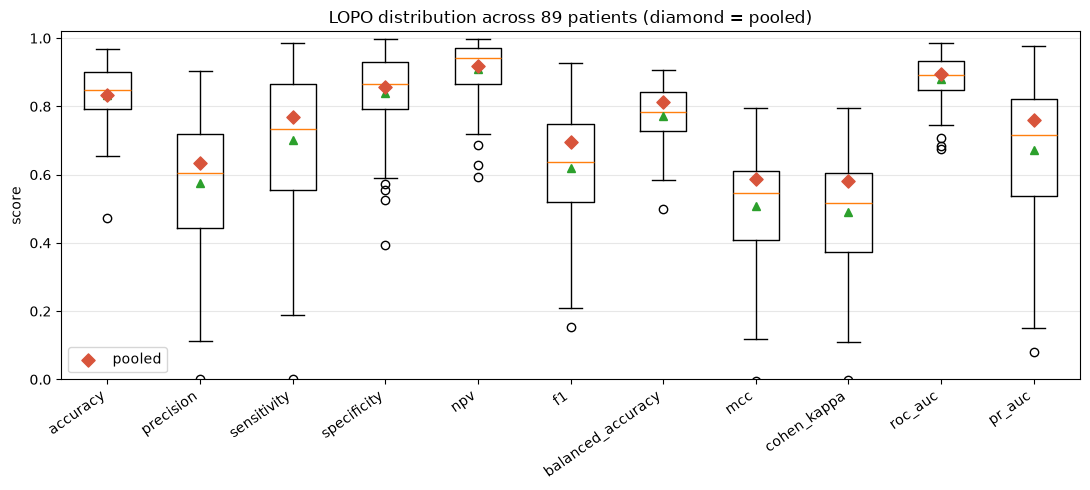

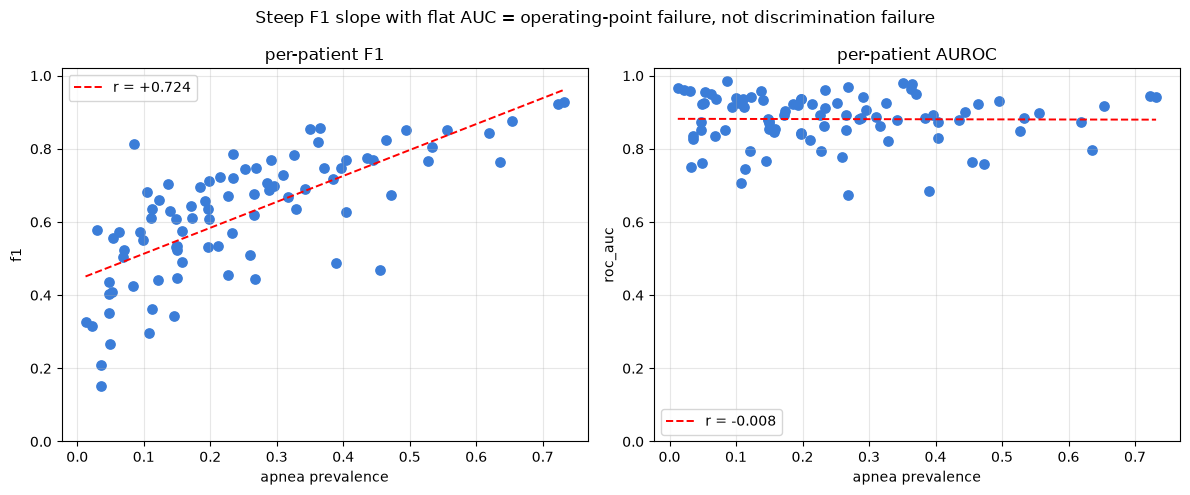

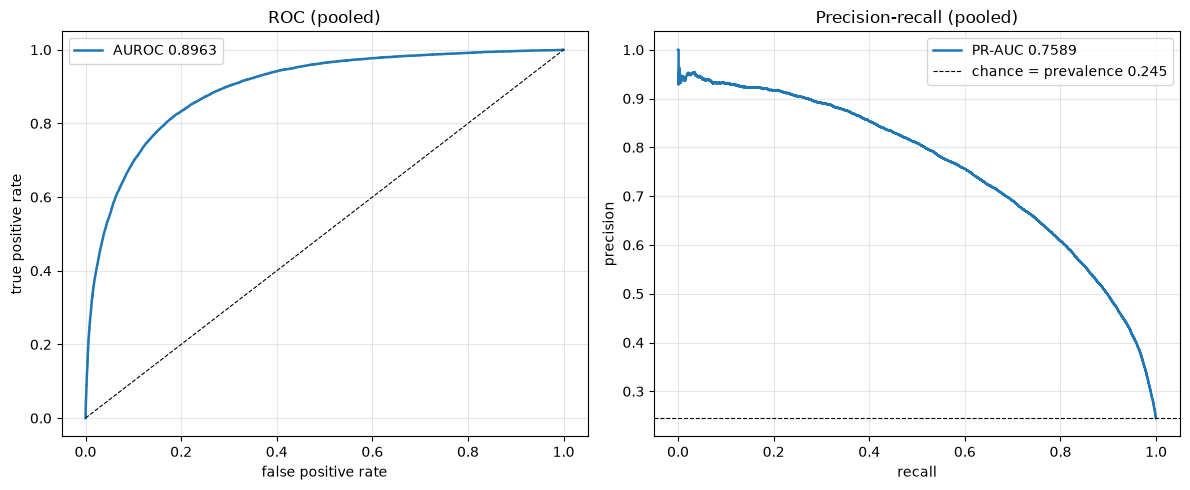

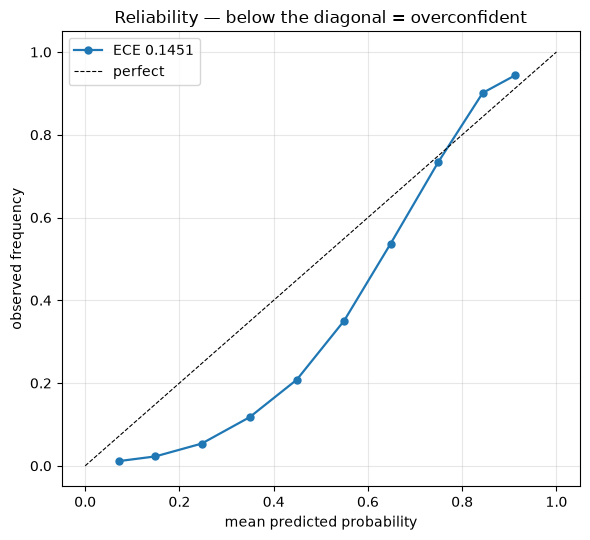

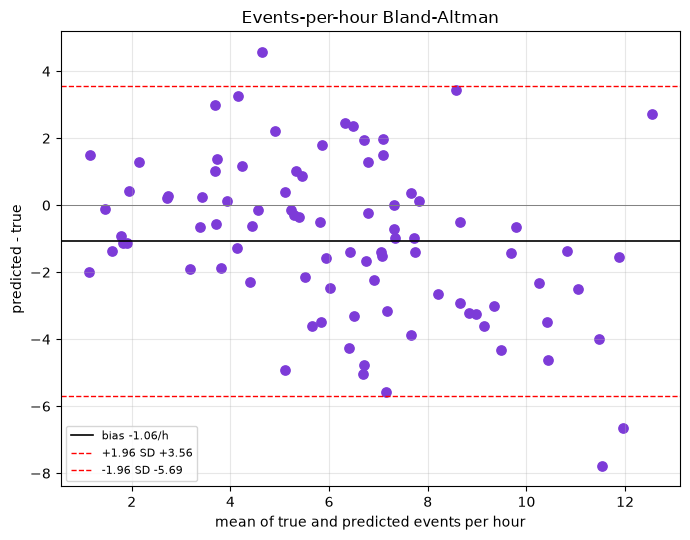

figures -> /home/nishant/apneastudyproject/leave_one_out_output/figures


In [13]:
# =========================================================================
# CELL 11 — figures
# =========================================================================
def _save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

show = [c for c in ["accuracy", "precision", "sensitivity", "specificity", "npv",
                    "f1", "balanced_accuracy", "mcc", "cohen_kappa", "roc_auc", "pr_auc"]
        if LOPO[c].notna().any()]

# 1 -- distribution across folds
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([LOPO[c].dropna().values for c in show], tick_labels=show, showmeans=True)
ax.scatter(range(1, len(show) + 1), [POOLED[c] for c in show],
           marker="D", s=45, c="#d8543b", zorder=5, label="pooled")
ax.set_ylabel("score"); ax.set_ylim(0, 1.02); ax.grid(axis="y", alpha=.3)
ax.set_title(f"LOPO distribution across {len(LOPO)} patients (diamond = pooled)")
ax.legend(); plt.xticks(rotation=35, ha="right")
_save(fig, "01_metric_distribution")

# 2 -- THE key figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, col, ttl in ((axes[0], "f1", "per-patient F1"), (axes[1], "roc_auc", "per-patient AUROC")):
    ok = LOPO[[col, "prevalence"]].dropna()
    ax.scatter(ok.prevalence, ok[col], s=45, c="#3b7dd8")
    if len(ok) > 2:
        z = np.polyfit(ok.prevalence, ok[col], 1)
        xs = np.linspace(ok.prevalence.min(), ok.prevalence.max(), 20)
        ax.plot(xs, np.polyval(z, xs), "r--", lw=1.4,
                label=f"r = {np.corrcoef(ok.prevalence, ok[col])[0,1]:+.3f}")
        ax.legend()
    ax.set_xlabel("apnea prevalence"); ax.set_ylabel(col)
    ax.set_title(ttl); ax.set_ylim(0, 1.02); ax.grid(alpha=.3)
fig.suptitle("Steep F1 slope with flat AUC = operating-point failure, not discrimination failure")
_save(fig, "02_f1_vs_auc_by_prevalence")

# 3 -- pooled ROC and PR
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(ALL_LAB, ALL_PROB)
axes[0].plot(fpr, tpr, lw=1.8, label=f"AUROC {POOLED['roc_auc']:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=.8)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC (pooled)"); axes[0].legend(); axes[0].grid(alpha=.3)
pr, rc, _ = precision_recall_curve(ALL_LAB, ALL_PROB)
axes[1].plot(rc, pr, lw=1.8, label=f"PR-AUC {POOLED['pr_auc']:.4f}")
axes[1].axhline(ALL_LAB.mean(), ls="--", c="k", lw=.8,
                label=f"chance = prevalence {ALL_LAB.mean():.3f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall (pooled)"); axes[1].legend(); axes[1].grid(alpha=.3)
_save(fig, "03_roc_pr")

# 4 -- reliability
edges = np.linspace(0, 1, N_CALIB_BINS + 1)
xs, ys = [], []
for i in range(N_CALIB_BINS):
    hi = ALL_PROB <= edges[i + 1] if i == N_CALIB_BINS - 1 else ALL_PROB < edges[i + 1]
    m = (ALL_PROB >= edges[i]) & hi
    if m.any():
        xs.append(ALL_PROB[m].mean()); ys.append(ALL_LAB[m].mean())
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(xs, ys, "o-", lw=1.6, ms=5, label=f"ECE {POOLED['ece']:.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=.8, label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed frequency")
ax.set_title("Reliability — below the diagonal = overconfident")
ax.legend(); ax.grid(alpha=.3)
_save(fig, "04_calibration")

# 5 -- Events-per-hour Bland-Altman
if len(LOPO) > 2:
    d = LOPO.pred_eph - LOPO.true_eph
    mn = (LOPO.pred_eph + LOPO.true_eph) / 2
    bias, sd = d.mean(), d.std(ddof=1)
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.scatter(mn, d, s=45, c="#7d3bd8")
    ax.axhline(bias, c="k", lw=1.2, label=f"bias {bias:+.2f}/h")
    ax.axhline(bias + 1.96 * sd, c="r", ls="--", lw=1, label=f"+1.96 SD {bias+1.96*sd:+.2f}")
    ax.axhline(bias - 1.96 * sd, c="r", ls="--", lw=1, label=f"-1.96 SD {bias-1.96*sd:+.2f}")
    ax.axhline(0, c="grey", lw=.7)
    ax.set_xlabel("mean of true and predicted events per hour")
    ax.set_ylabel("predicted - true"); ax.set_title("Events-per-hour Bland-Altman")
    ax.legend(fontsize=8); ax.grid(alpha=.3)
    _save(fig, "05_eph_bland_altman")

print(f"figures -> {FIG_DIR}")

## Cell 12 — Headline

The numbers to copy into a paper table, plus an inventory of what was written.

For the results section, report the **LOPO mean ± SD over 89 patients** as primary
(it is the honest per-patient estimate and n=89 is the sample size), with the pooled
value alongside. State the number of patients for which each metric was undefined —
leaving that out is the version that gets caught.

In [14]:
# =========================================================================
# CELL 12 — headline
# =========================================================================
print("=" * 78)
print(f"  LOPO — {len(LOPO)} patients | weighted focal (gamma={FOCAL_GAMMA}, "
      f"pos_weight cap {POS_WEIGHT_CAP:.0f})")
print("=" * 78)
head = ["accuracy", "precision", "sensitivity", "specificity", "npv", "f1",
        "balanced_accuracy", "mcc", "cohen_kappa", "roc_auc", "pr_auc", "ece"]
for m in head:
    r = SUMMARY[SUMMARY.metric == m]
    if not len(r):
        continue
    r = r.iloc[0]
    nd = f"  [{int(r.n_undefined)} undefined]" if r.n_undefined else ""
    print(f"  {m:20s} {r['mean']:.4f} +/- {r['std']:.4f}   "
          f"(pooled {r['pooled']:.4f}){nd}")

print(f"\n  mean threshold        {LOPO.threshold.mean():.3f} +/- {LOPO.threshold.std(ddof=1):.3f}")
print(f"  mean validation F1    {LOPO.val_f1.mean():.4f}")
print(f"  worst patient (F1)    {LOPO.loc[LOPO.f1.idxmin(), 'patient']} "
      f"= {LOPO.f1.min():.4f}")
print(f"  best  patient (F1)    {LOPO.loc[LOPO.f1.idxmax(), 'patient']} "
      f"= {LOPO.f1.max():.4f}")

print(f"\n  files in {OUT_DIR}")
for f in ("cohort.csv", "lopo_per_patient.csv", "lopo_summary.csv",
          "lopo_severity_strata.csv"):
    p = os.path.join(OUT_DIR, f)
    if os.path.exists(p):
        print(f"    {f:30s} {os.path.getsize(p)/1e3:7.1f} KB")
print(f"    folds/     {len(glob.glob(os.path.join(FOLD_DIR,'*.npz'))):3d} fold files")
print(f"    figures/   {len(glob.glob(os.path.join(FIG_DIR,'*.png'))):3d} PNGs")

if MAX_FOLDS is not None:
    print(f"\n  [!] MAX_FOLDS = {MAX_FOLDS}. Set it to None and re-run for all "
          f"{len(PIDS)} patients.\n      Completed folds are cached, so nothing "
          f"already trained is repeated.")

  LOPO — 89 patients | weighted focal (gamma=2.0, pos_weight cap 12)
  accuracy             0.8342 +/- 0.0874   (pooled 0.8343)
  precision            0.5753 +/- 0.1939   (pooled 0.6336)
  sensitivity          0.7018 +/- 0.2113   (pooled 0.7682)
  specificity          0.8405 +/- 0.1230   (pooled 0.8557)
  npv                  0.9108 +/- 0.0844   (pooled 0.9192)
  f1                   0.6187 +/- 0.1687   (pooled 0.6944)  [1 undefined]
  balanced_accuracy    0.7711 +/- 0.0842   (pooled 0.8120)
  mcc                  0.5082 +/- 0.1553   (pooled 0.5873)
  cohen_kappa          0.4898 +/- 0.1603   (pooled 0.5822)
  roc_auc              0.8812 +/- 0.0686   (pooled 0.8963)
  pr_auc               0.6729 +/- 0.2134   (pooled 0.7589)
  ece                  0.1682 +/- 0.0693   (pooled 0.1451)

  mean threshold        0.523 +/- 0.036
  mean validation F1    0.6254
  worst patient (F1)    SN5 = 0.1522
  best  patient (F1)    SN26 = 0.9285

  files in /home/nishant/apneastudyproject/leave_one_out_out

  TEST LOSS ACROSS 89 FOLDS  (weighted focal, gamma=2.0)
                mean       std       min    median       max argmin argmax
focal_loss    0.1778    0.1024    0.0298    0.1640    0.6299   SN41   SN98
bce_loss      0.4202    0.1172    0.1724    0.4173    0.8866   SN38   SN11

---- BY SEVERITY ----
severity  n  prevalence  focal_mean  focal_min  focal_max  bce_mean
  normal 30      0.1096      0.1121     0.0298     0.4346    0.3352
    mild 57      0.3121      0.2004     0.0987     0.6299    0.4603
moderate  2      0.4294      0.5159     0.4032     0.6287    0.5516


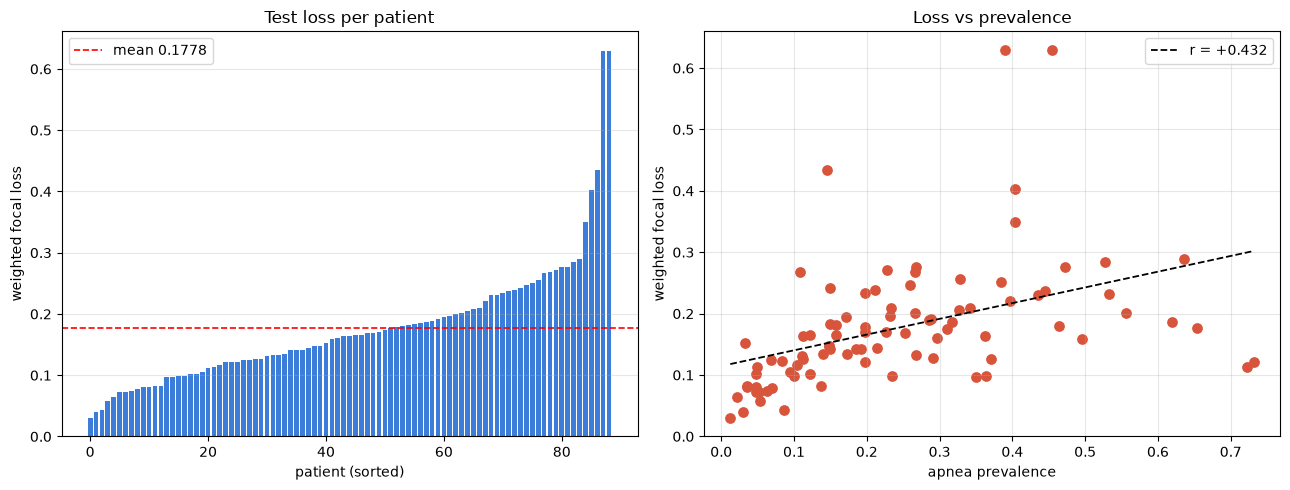

In [15]:
# =========================================================================
# CELL 13 — loss statistics across folds (test loss, from the saved folds)
# =========================================================================
def weighted_focal_np(labels, probs, pos_weight, gamma=FOCAL_GAMMA, eps=1e-7):
    """Same loss as training, in numpy. Mean over the patient's epochs."""
    y = np.asarray(labels, np.float64)
    p = np.clip(np.asarray(probs, np.float64), eps, 1 - eps)
    pos = pos_weight * y * (1 - p) ** gamma * np.log(p)
    neg = (1 - y) * p ** gamma * np.log(1 - p)
    return float(-(pos + neg).mean())


def bce_np(labels, probs, eps=1e-7):
    y = np.asarray(labels, np.float64)
    p = np.clip(np.asarray(probs, np.float64), eps, 1 - eps)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())


rows = []
for pid in LOPO.patient:
    fp = fold_path(pid)
    if not os.path.exists(fp):
        continue
    with np.load(fp) as z:
        lab, prob = z["labels"], z["probs"]
    tr_p, _, _ = make_fold(pid)                       # deterministic -> exact
    n1 = int(sum(int(CACHE[p]["y"].sum()) for p in tr_p))
    n0 = int(sum(len(CACHE[p]["y"]) for p in tr_p)) - n1
    pw = float(min(n0 / max(1, n1), POS_WEIGHT_CAP))
    rows.append(dict(patient=pid, n_epochs=len(lab), prevalence=float(lab.mean()),
                     pos_weight=pw,
                     focal_loss=weighted_focal_np(lab, prob, pw),
                     bce_loss=bce_np(lab, prob),
                     severity=SEVERITY_NAMES[severity_of(events_per_hour(lab))]))

LOSS = pd.DataFrame(rows)
LOSS.to_csv(os.path.join(OUT_DIR, "loss_per_fold.csv"), index=False)

print("=" * 78)
print(f"  TEST LOSS ACROSS {len(LOSS)} FOLDS  (weighted focal, gamma={FOCAL_GAMMA})")
print("=" * 78)
stats = LOSS[["focal_loss", "bce_loss"]].agg(["mean", "std", "min", "median", "max"]).T
stats["argmin"] = [LOSS.loc[LOSS[c].idxmin(), "patient"] for c in stats.index]
stats["argmax"] = [LOSS.loc[LOSS[c].idxmax(), "patient"] for c in stats.index]
print(stats.to_string(float_format=lambda v: f"{v:9.4f}"))

_ord = {n: i for i, n in enumerate(SEVERITY_NAMES)}
print("\n---- BY SEVERITY ----")
print(LOSS.groupby("severity")
        .agg(n=("patient", "count"), prevalence=("prevalence", "mean"),
             focal_mean=("focal_loss", "mean"), focal_min=("focal_loss", "min"),
             focal_max=("focal_loss", "max"), bce_mean=("bce_loss", "mean"))
        .reset_index().sort_values("severity", key=lambda s: s.map(_ord))
        .to_string(index=False, float_format=lambda v: f"{v:9.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(range(len(LOSS)), LOSS.sort_values("focal_loss").focal_loss, color="#3b7dd8")
axes[0].axhline(LOSS.focal_loss.mean(), c="r", ls="--", lw=1.2,
                label=f"mean {LOSS.focal_loss.mean():.4f}")
axes[0].set_xlabel("patient (sorted)"); axes[0].set_ylabel("weighted focal loss")
axes[0].set_title("Test loss per patient"); axes[0].legend(); axes[0].grid(axis="y", alpha=.3)

axes[1].scatter(LOSS.prevalence, LOSS.focal_loss, s=45, c="#d8543b")
if len(LOSS) > 2:
    r = np.corrcoef(LOSS.prevalence, LOSS.focal_loss)[0, 1]
    z = np.polyfit(LOSS.prevalence, LOSS.focal_loss, 1)
    xs = np.linspace(LOSS.prevalence.min(), LOSS.prevalence.max(), 20)
    axes[1].plot(xs, np.polyval(z, xs), "k--", lw=1.3, label=f"r = {r:+.3f}")
    axes[1].legend()
axes[1].set_xlabel("apnea prevalence"); axes[1].set_ylabel("weighted focal loss")
axes[1].set_title("Loss vs prevalence"); axes[1].grid(alpha=.3)
_save(fig, "06_loss_per_fold")